# NFGS manuscript experiments

One overview of a complete reconstruction campaign. The default dataset is **archived manuscript summary tables**. Set `RESULT_ROOT` below to a freshly generated campaign directory to view new results. Missing outputs remain visible; archived values are never silently substituted.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'nfgs_solver.py').exists())
sys.path.insert(0, str(ROOT))
from nfgs.analysis import *
RESULT_ROOT = ROOT / 'reference_results'  # change to ROOT / 'results/paper' for a fresh campaign
DATA_KIND = 'Archived manuscript tables' if RESULT_ROOT == ROOT / 'reference_results' else 'Fresh campaign outputs'
print(DATA_KIND, RESULT_ROOT.relative_to(ROOT))
tables, missing = load_tables(RESULT_ROOT)
display(pd.DataFrame({'dataset': list(tables), 'rows': [len(v) for v in tables.values()]}))
print('Missing stages:', missing or 'none')
if (RESULT_ROOT / 'campaign_state.json').exists():
    state = json.loads((RESULT_ROOT / 'campaign_state.json').read_text())
    display(pd.DataFrame([dict(experiment=k, status=v['status'], seconds=v.get('wall_time_s')) for k,v in state['experiments'].items()]))
plt.rcParams.update({'font.size': 12, 'text.color': 'black', 'axes.labelcolor': 'black'})

Archived manuscript tables reference_results


,dataset,rows
0,td,300
1,runtime,33
2,low_lou_fp32,3
3,low_lou_fp64,3
4,height,1320
5,budgets,60
6,topology,39
7,twist,36
8,helicity,36
9,selection,33


Missing stages: none


## Physical and numerical protocol

The input grids, source parameters, masks, current operator and stopping rule are explicit. A quick profile is a numerical check, not a replacement for the manuscript campaign.

In [2]:
protocol=json.loads((ROOT/'configs/paper_protocol.json').read_text())
display(protocol)

{'schema_version': 1,
 'rho_grid': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
 'low_lou_rho': 0.5,
 'precision': 'float32',
 'precision_comparison': 'float64',
 'stopping': {'mode': 'sigma_best',
  'max_iter': 3000,
  'tolerance': 1e-05,
  'patience': 40,
  'improvement_tolerance': 1e-05,
  'selected_state': 'best_sigma'},
 'horizontal_zero_mode': 'frozen_linear_harmonic',
 'vertical_current': 'staggered_face',
 'poloidal_update': 'direct',
 'scoring_current': 'common_fd2_curl',
 'TD_cases': {'td1': {'parameters': {'R': 110.0,
    'a': 35.0,
    'L': 100.0,
    'd': 50.0,
    'q': 100.0,
    'I0': -13.0,
    'Nt': 2.577,
    'l_i': 0.5,
    'p_Bt_ratio': 1.0},
   'grid_nodes_xyz': [151, 251, 101]},
  'td2': {'parameters': {'R': 100.0,
    'a': 35.0,
    'L': 60.0,
    'd': 60.0,
    'q': 80.0,
    'I0': -3.0,
    'Nt': 8.8,
    'l_i': 0.5,
    'p_Bt_ratio': 1.0},
   'grid_nodes_xyz': [151, 251, 101]},
  'td3': {'parameters': {'R': 110.0,
    'a': 32.5,
    'L': 50.0,
    

## CCI fidelity and force-freeness

The ring marks rho = 0.5. Every plotted current residual uses the common second-order curl and the primary scoring domain.

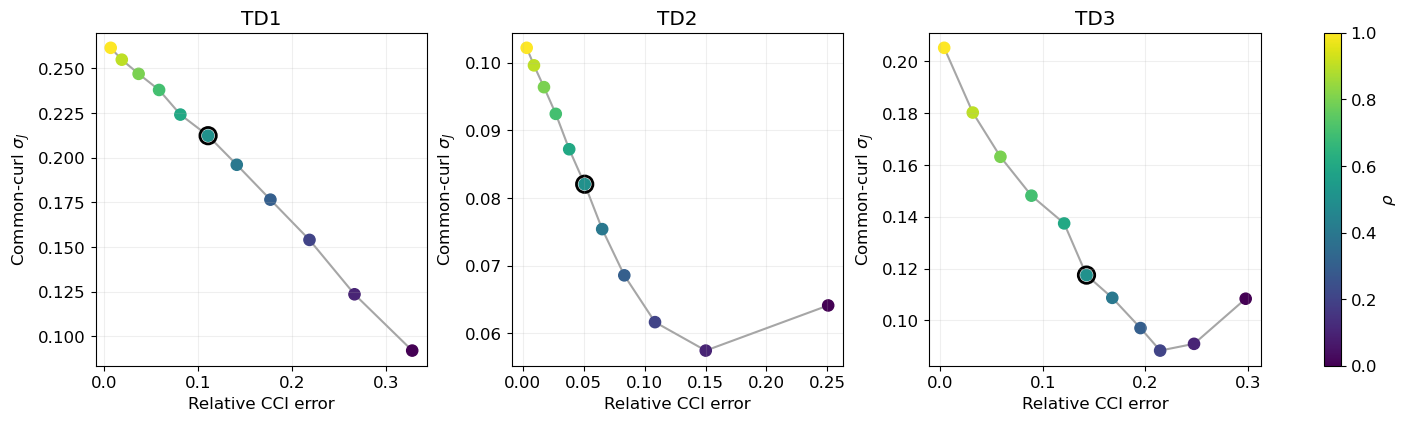

,benchmark,rho,E_rel_Bgt_domain,sigma_J
55,td1,0.5,0.110775,0.212295
157,td2,0.5,0.050771,0.082051
255,td3,0.5,0.142478,0.117488


In [3]:
td=primary_td(tables['td']) if 'td' in tables else pd.DataFrame()
if not td.empty:
    plot_tradeoff(td); plt.show()
    display(td[np.isclose(td.rho,.5)][['benchmark','rho','E_rel_Bgt_domain','sigma_J']])

## Agreement with the three-dimensional reference field

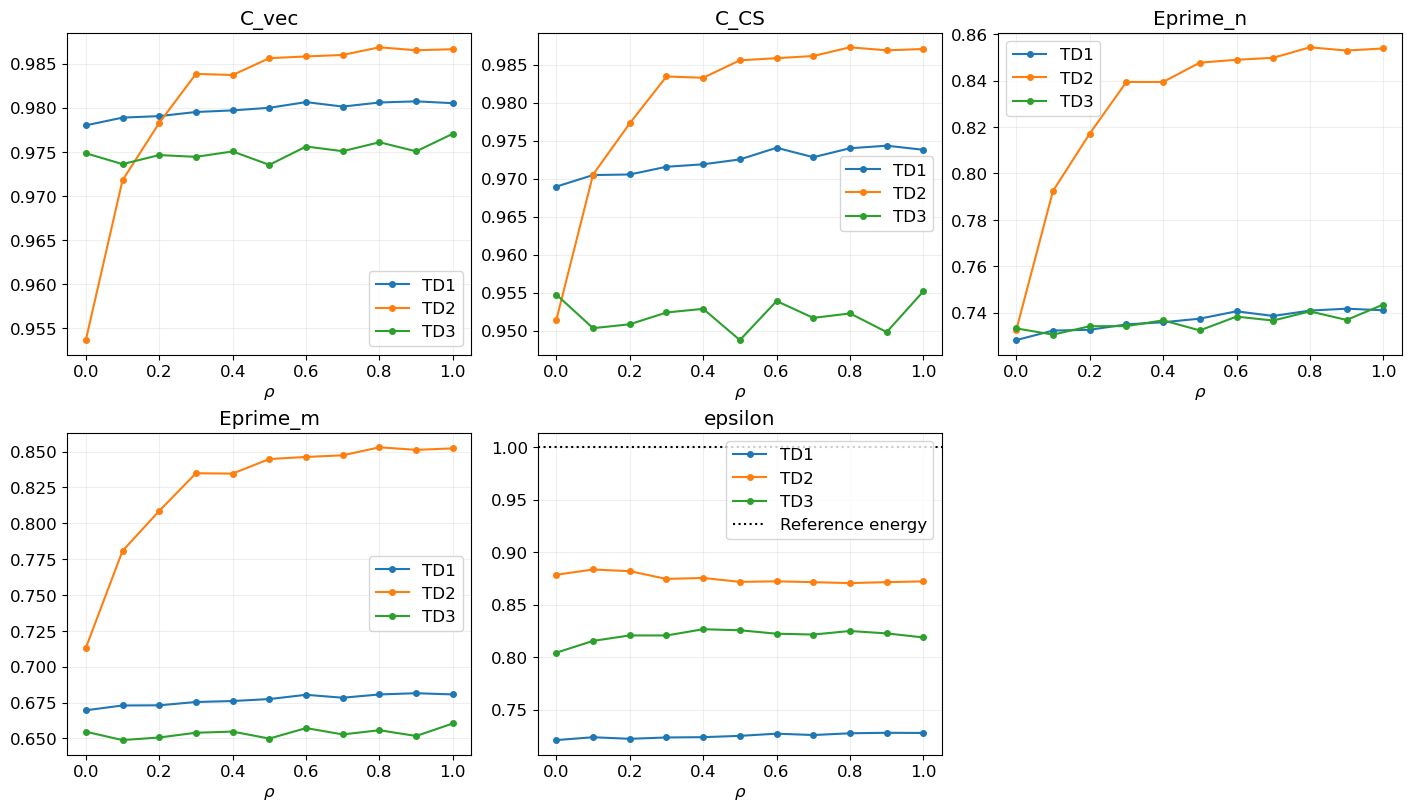

,benchmark,C_vec,C_CS,Eprime_n,Eprime_m,epsilon
55,td1,0.980002,0.972541,0.737445,0.677436,0.724911
157,td2,0.985634,0.985581,0.847707,0.844845,0.871709
255,td3,0.973525,0.948776,0.732377,0.649878,0.825579


In [4]:
if not td.empty:
    plot_field_metrics(td); plt.show()
    display(td[np.isclose(td.rho,.5)][['benchmark','C_vec','C_CS','Eprime_n','Eprime_m','epsilon']])

## Published NFPT, VFVP and SSW comparison

These are published scores from Yi et al. (2022), not results from a new execution of those solvers. Field agreement improves most consistently for TD1 and TD2; the original current diagnostic retains its published discretization.

In [5]:
published=pd.read_csv(ROOT/'reference_results/published_methods.csv')
display(published)
if not td.empty:
    selected=td[np.isclose(td.rho,.5)].merge(published[published.method=='NFPT'],left_on='benchmark',right_on=published[published.method=='NFPT']['case'].str.lower(),suffixes=('_NFGS','_NFPT'))
    metrics=['C_vec','C_CS','Eprime_n','Eprime_m','epsilon']
    for metric in metrics:
        left=selected[metric+'_NFGS']; right=selected[metric+'_NFPT']
        selected[metric+'_better']='NFGS'
        selected.loc[(abs(left-1)>=abs(right-1)) if metric=='epsilon' else (left<=right),metric+'_better']='NFPT'
    display(selected[['benchmark']+[k+'_better' for k in metrics]])

,case,method,C_vec,C_CS,Eprime_n,Eprime_m,epsilon,sigma_J
0,TD1,NFPT,0.935,0.898,0.590,0.534,0.643,0.102
1,TD1,VFVP,0.947,0.946,0.671,0.628,0.739,0.298
2,TD1,SSW,0.920,0.942,0.556,0.472,0.537,0.662
3,TD2,NFPT,0.985,0.987,0.832,0.833,0.803,0.045
4,TD2,VFVP,0.923,0.931,0.630,0.627,0.605,0.172
5,TD2,SSW,0.891,0.943,0.569,0.560,0.482,0.366
6,TD3,NFPT,0.978,0.968,0.765,0.725,0.788,0.094
7,TD3,SSW,0.958,0.972,0.672,0.586,0.659,0.388


,benchmark,C_vec_better,C_CS_better,Eprime_n_better,Eprime_m_better,epsilon_better
0,td1,NFGS,NFGS,NFGS,NFGS,NFGS
1,td2,NFGS,NFPT,NFGS,NFGS,NFGS
2,td3,NFPT,NFPT,NFPT,NFPT,NFGS


## Runtime

These are measured solver intervals on the recorded hardware, without a hardware-matched claim of speedup over Fortran NFPT.

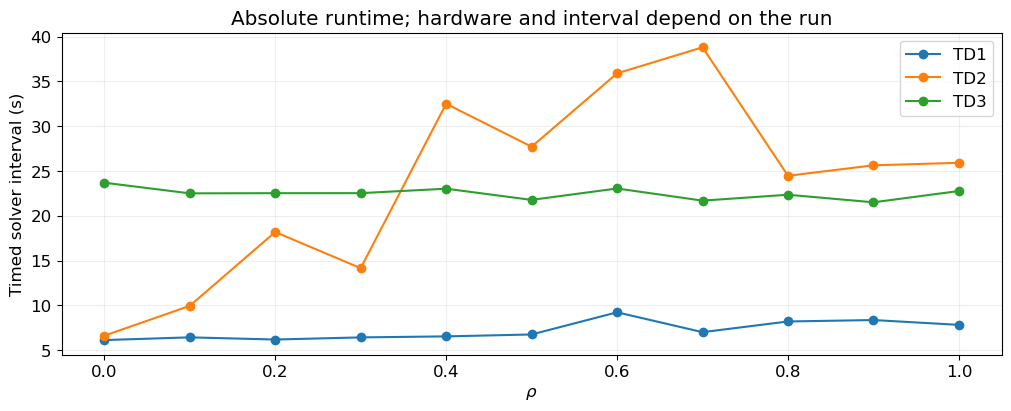

In [6]:
if 'runtime' in tables:
    plot_runtime(tables['runtime']); plt.show()

## Independent Low–Lou family at rho = 0.5

The common curl uses separate dx, dy and dz. The three source profiles are retained in both precisions.

low_lou_fp32


,benchmark,C_vec,C_CS,Eprime_n,Eprime_m,epsilon,sigma_J_common_fd2
0,low_lou_c2,0.995149,0.901085,0.797309,0.531659,1.001672,0.094563
1,low_lou_ll1,0.991230,0.805923,0.743991,0.422121,0.980512,0.125305
2,low_lou_ll2,0.998079,0.924481,0.801426,-0.537062,1.036560,0.106378


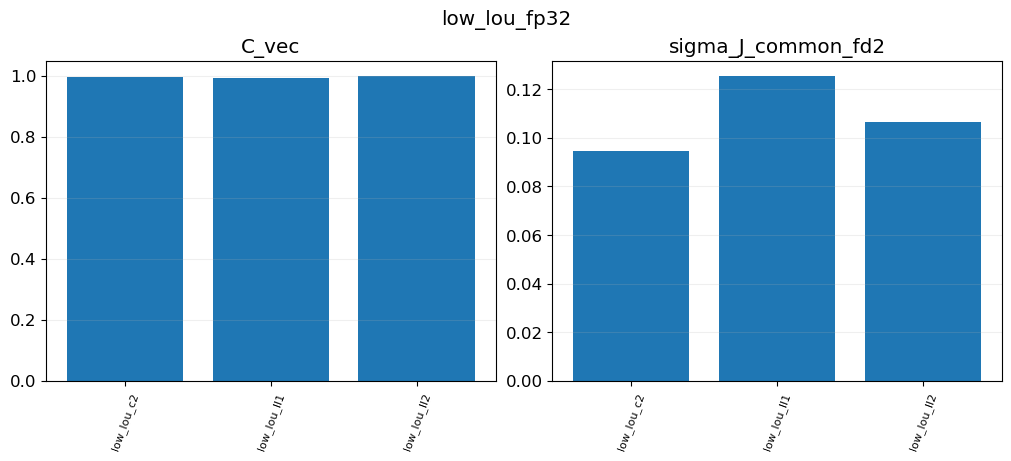

low_lou_fp64


,benchmark,C_vec,C_CS,Eprime_n,Eprime_m,epsilon,sigma_J_common_fd2
0,low_lou_c2,0.995121,0.901288,0.797094,0.532663,1.001449,0.095379
1,low_lou_ll1,0.991202,0.806327,0.743941,0.423518,0.980262,0.125580
2,low_lou_ll2,0.998079,0.924366,0.801517,-0.534404,1.036559,0.106373


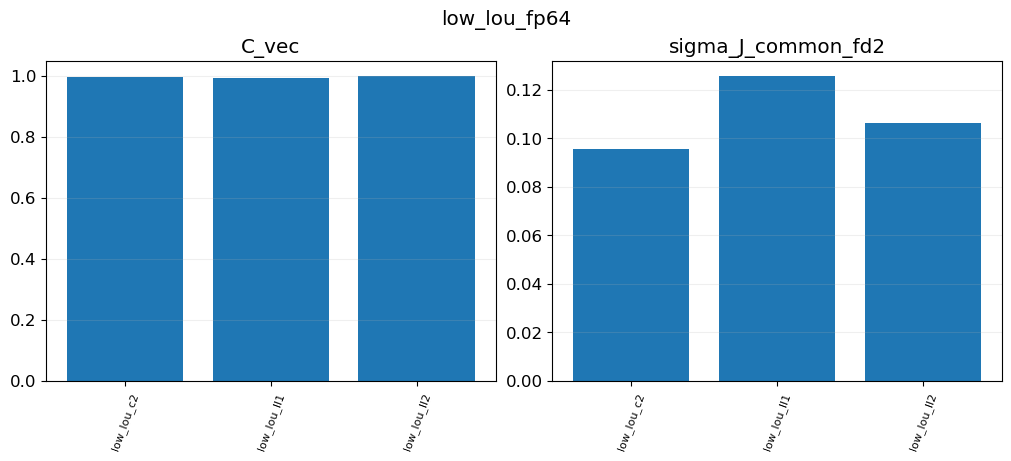

In [7]:
for key in ['low_lou_fp32','low_lou_fp64']:
    if key in tables:
        print(key)
        display(tables[key][['benchmark','C_vec','C_CS','Eprime_n','Eprime_m','epsilon','sigma_J_common_fd2']])
        plot_grouped(tables[key],['C_vec','sigma_J_common_fd2'],key); plt.show()

## Height-dependent residual and boundary contributions

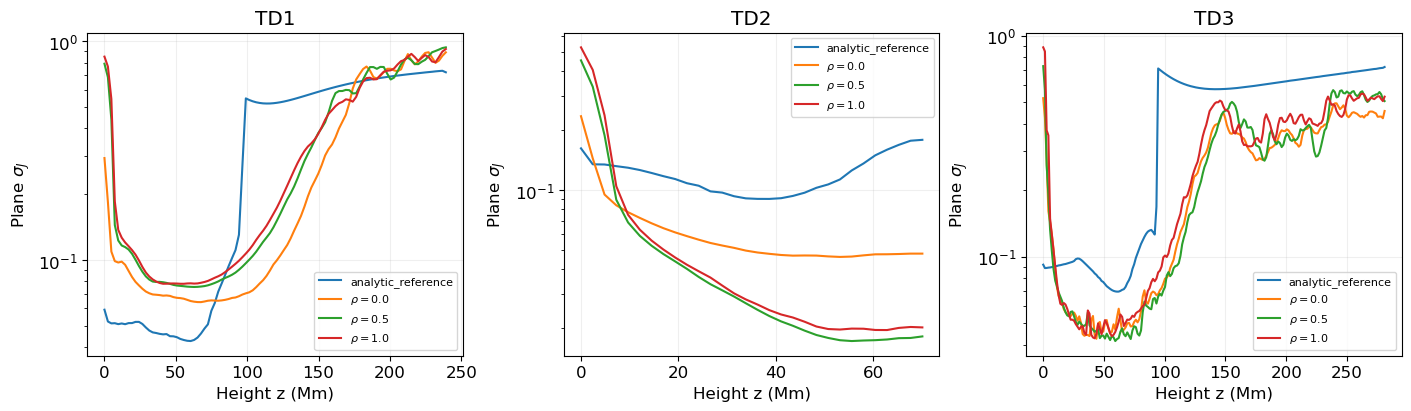

,benchmark,method,region,sigma_J_region,numerator_fraction,current_fraction
0,td1,analytic_reference,bottom,0.059116,2.721152e-02,2.325263e-02
1,td1,analytic_reference,first_row,0.052198,2.426404e-02,2.348214e-02
2,td1,analytic_reference,lateral,0.786970,1.346333e-03,8.642089e-05
3,td1,analytic_reference,top,0.729605,1.038902e-05,7.193017e-07
4,td1,analytic_reference,bulk,0.050197,9.471677e-01,9.531781e-01
5,td1,nfgs_rho_0.0,bottom,0.292488,8.327602e-02,2.619689e-02
6,td1,nfgs_rho_0.0,first_row,0.183749,4.653918e-02,2.330403e-02
7,td1,nfgs_rho_0.0,lateral,0.788644,6.922500e-02,8.076443e-03
8,td1,nfgs_rho_0.0,top,0.875265,3.761490e-03,3.954202e-04
9,td1,nfgs_rho_0.0,bulk,0.077865,7.971983e-01,9.420272e-01


In [8]:
if 'height' in tables:
    plot_height(tables['height']); plt.show()
if 'budgets' in tables: display(tables['budgets'])

## Field-line connectivity and high-Q overlap

,benchmark,method,field_smoothing_sigma_cells,seed_protocol,high_logq,valid_pixels,logq_mae,logq_rmse,logq_pearson,reference_high_q_pixels,...,high_q_intersection_pixels,high_q_union_pixels,high_q_dice,high_q_jaccard,endpoint_valid_seeds,endpoint_valid_fraction,endpoint_pair_rmse,endpoint_pair_mae,endpoint_pair_p95,endpoint_boundary_pair_match_fraction
0,td1,analytic_reference,0.0,every_node_on_photosphere_half_cell_inside,3.0,35054,0.000000,0.000000,1.000000,17,...,17,17,1.000000,1.000000,37338,0.995680,0.000000,0.000000,0.000000,1.000000
1,td1,nfpt_fortran_symmetric,0.0,every_node_on_photosphere_half_cell_inside,3.0,33193,0.266890,0.411887,0.419311,17,...,0,35,0.000000,0.000000,37314,0.995040,192.757295,92.902412,497.659464,0.616069
2,td1,nfgs_rho_0.0,0.0,every_node_on_photosphere_half_cell_inside,3.0,33254,0.233825,0.377522,0.451560,17,...,0,20,0.000000,0.000000,37323,0.995280,171.230087,77.220023,477.210914,0.686467
3,td1,nfgs_rho_0.1,0.0,every_node_on_photosphere_half_cell_inside,3.0,33254,0.234319,0.380657,0.447826,17,...,0,24,0.000000,0.000000,37313,0.995013,170.697039,76.928175,476.846246,0.687937
4,td1,nfgs_rho_0.2,0.0,every_node_on_photosphere_half_cell_inside,3.0,33246,0.238502,0.384469,0.434335,17,...,0,27,0.000000,0.000000,37317,0.995120,170.656965,77.167273,476.802648,0.686604
5,td1,nfgs_rho_0.3,0.0,every_node_on_photosphere_half_cell_inside,3.0,33240,0.236775,0.380817,0.441944,17,...,0,22,0.000000,0.000000,37319,0.995173,170.271022,76.884077,476.369895,0.688362
6,td1,nfgs_rho_0.4,0.0,every_node_on_photosphere_half_cell_inside,3.0,33228,0.237962,0.381032,0.441107,17,...,0,24,0.000000,0.000000,37312,0.994987,170.094886,76.855983,476.137569,0.688492
7,td1,nfgs_rho_0.5,0.0,every_node_on_photosphere_half_cell_inside,3.0,33233,0.238128,0.381110,0.441139,17,...,0,23,0.000000,0.000000,37316,0.995093,170.067089,76.875406,476.092782,0.688927
8,td1,nfgs_rho_0.6,0.0,every_node_on_photosphere_half_cell_inside,3.0,33222,0.234689,0.379060,0.450637,17,...,0,22,0.000000,0.000000,37313,0.995013,169.568080,76.409736,475.793830,0.691046
9,td1,nfgs_rho_0.7,0.0,every_node_on_photosphere_half_cell_inside,3.0,33215,0.239540,0.382003,0.437868,17,...,0,23,0.000000,0.000000,37310,0.994933,169.701770,76.731040,475.659231,0.688850


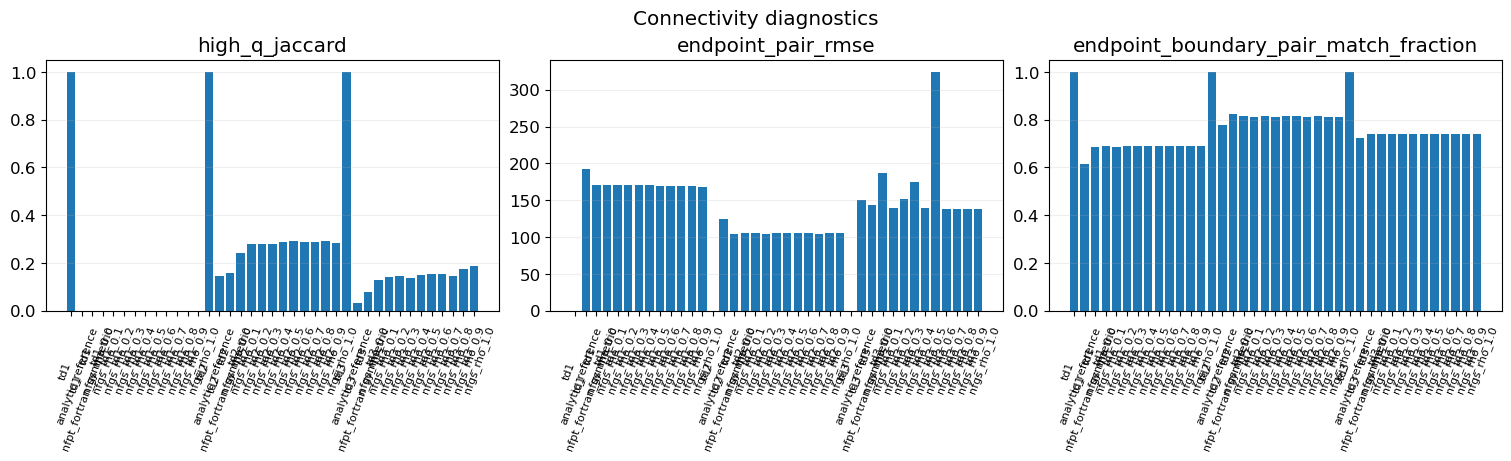

,benchmark,rho,high_logq,valid_pixels,logq_mae,logq_rmse,logq_pearson,reference_high_q_pixels,candidate_high_q_pixels,high_q_intersection_pixels,high_q_union_pixels,high_q_dice,high_q_jaccard
0,td1,0.0,2.0,33254,0.233825,0.377522,0.451560,508,167,69,606,0.204444,0.113861
1,td1,0.5,2.0,33233,0.238128,0.381110,0.441139,504,188,91,601,0.263006,0.151414
2,td1,1.0,2.0,33199,0.238538,0.381352,0.442249,502,205,106,601,0.299859,0.176373
3,td1,0.0,2.5,33254,0.233825,0.377522,0.451560,177,27,0,204,0.000000,0.000000
4,td1,0.5,2.5,33233,0.238128,0.381110,0.441139,175,22,1,196,0.010152,0.005102
5,td1,1.0,2.5,33199,0.238538,0.381352,0.442249,174,17,1,190,0.010471,0.005263
6,td1,0.0,3.0,33254,0.233825,0.377522,0.451560,17,3,0,20,0.000000,0.000000
7,td1,0.5,3.0,33233,0.238128,0.381110,0.441139,17,6,0,23,0.000000,0.000000
8,td1,1.0,3.0,33199,0.238538,0.381352,0.442249,17,5,0,22,0.000000,0.000000
9,td2,0.0,2.0,33028,0.286397,0.486316,0.547024,698,624,194,1128,0.293495,0.171986


In [9]:
if 'topology' in tables:
    display(tables['topology'])
    plot_grouped(tables['topology'],['high_q_jaccard','endpoint_pair_rmse','endpoint_boundary_pair_match_fraction'],'Connectivity diagnostics'); plt.show()
if 'Q_threshold' in tables: display(tables['Q_threshold'])

## Twist-core location and amplitude

,benchmark,method,reference_peak_x_mm,reference_peak_z_mm,reference_peak_Tw,reference_core_apex_x_mm,reference_core_apex_z_mm,reference_core_area_pixels,peak_x_mm,peak_z_mm,...,peak_abs_Tw_relative_error,peak_displacement_mm,core_apex_x_mm,core_apex_z_mm,core_apex_displacement_mm,core_apex_height_error_mm,core_nearest_distance_mm,core_area_pixels,core_threshold_abs_Tw,search_radius_mm
0,td1,analytic_reference,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,-13.288591,89.395973,...,0.000000,0.000000,1.421085e-14,96.644295,0.000000,0.000000,0.0,676,0.349400,70.0
1,td1,nfgs_rho_0.0,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,-3.624161,89.395973,...,0.181068,9.664430,-1.208054e+00,128.053691,31.432619,31.409396,0.0,980,0.349400,70.0
2,td1,nfgs_rho_0.1,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,3.624161,94.228188,...,0.171746,17.589527,1.421085e-14,125.637584,28.993289,28.993289,0.0,948,0.349400,70.0
3,td1,nfgs_rho_0.2,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,3.624161,91.812081,...,0.184261,17.084459,1.421085e-14,123.221477,26.577181,26.577181,0.0,940,0.349400,70.0
4,td1,nfgs_rho_0.3,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,-1.208054,89.395973,...,0.180050,12.080537,1.421085e-14,123.221477,26.577181,26.577181,0.0,929,0.349400,70.0
5,td1,nfgs_rho_0.4,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,-3.624161,91.812081,...,0.180437,9.961866,1.421085e-14,123.221477,26.577181,26.577181,0.0,919,0.349400,70.0
6,td1,nfgs_rho_0.5,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,3.624161,91.812081,...,0.176249,17.084459,1.421085e-14,120.805369,24.161074,24.161074,0.0,907,0.349400,70.0
7,td1,nfgs_rho_0.6,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,-1.208054,99.060403,...,0.165005,15.470636,1.421085e-14,118.389262,21.744966,21.744966,0.0,890,0.349400,70.0
8,td1,nfgs_rho_0.7,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,1.208054,86.979866,...,0.180456,14.696607,1.208054e+00,120.805369,24.191256,24.161074,0.0,906,0.349400,70.0
9,td1,nfgs_rho_0.8,-13.288591,89.395973,0.873499,1.421085e-14,96.644295,676,-3.624161,94.228188,...,0.166726,10.805161,1.421085e-14,118.389262,21.744966,21.744966,0.0,890,0.349400,70.0


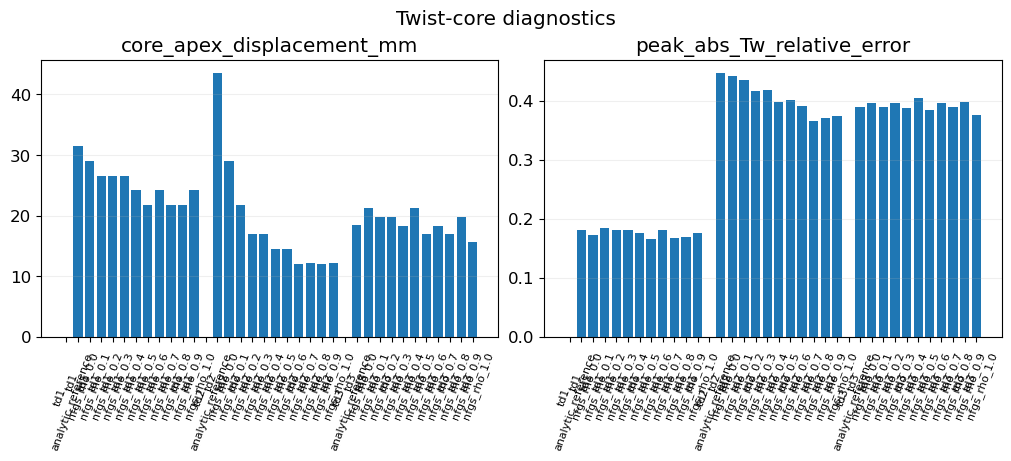

In [10]:
if 'twist' in tables:
    display(tables['twist'])
    plot_grouped(tables['twist'],['core_apex_displacement_mm','peak_abs_Tw_relative_error'],'Twist-core diagnostics'); plt.show()

## Six-face energy and current-carrying helicity

,benchmark,method,rho,domain,total_energy_common,potential_energy_6face,free_energy_6face,free_energy_over_potential,helmholtz_non_solenoidal_energy,helmholtz_non_solenoidal_energy_fraction,...,helicity_gauge,field_devore_bottom_bz_mean_removed,field_devore_curl_relative_rms,potential_devore_bottom_bz_mean_removed,potential_devore_curl_relative_rms,total_energy_common_relative_difference,potential_energy_6face_relative_difference,free_energy_6face_relative_difference,relative_helicity_6face_relative_difference,current_carrying_helicity_fraction_abs_relative_difference
0,td1,analytic_reference,NaN,protocol,2602.634539,2262.940862,339.693677,0.150112,0.000502,1.927266e-07,...,common_devore_Az_zero,0.000311,0.016400,0.000310,0.019704,0.000000,0.000000,0.000000,0.000000,0.000000
1,td1,nfgs_rho_1.0,1.0,protocol,1893.908929,1604.371199,289.537730,0.180468,0.000800,4.222560e-07,...,common_devore_Az_zero,0.000311,0.019077,0.000311,0.028068,-0.272311,-0.291024,-0.147651,-0.154070,-0.053710
2,td1,nfgs_rho_0.5,0.5,protocol,1886.689667,1596.278403,290.411264,0.181930,0.000732,3.880130e-07,...,common_devore_Az_zero,0.000311,0.018976,0.000310,0.026137,-0.275085,-0.294600,-0.145079,-0.149728,-0.020785
3,td1,nfgs_rho_0.1,0.1,protocol,1883.315293,1581.912938,301.402354,0.190530,0.000723,3.838314e-07,...,common_devore_Az_zero,0.000311,0.018886,0.000310,0.023967,-0.276381,-0.300948,-0.112723,-0.130077,0.060822
4,td1,nfgs_rho_0.0,0.0,protocol,1876.234457,1572.212405,304.022052,0.193372,0.000718,3.827508e-07,...,common_devore_Az_zero,0.000311,0.018919,0.000310,0.023681,-0.279102,-0.305235,-0.105011,-0.122255,0.086466
5,td2,analytic_reference,NaN,protocol,332.358240,210.669189,121.689051,0.577631,0.001556,4.682351e-06,...,common_devore_Az_zero,-0.000750,0.040733,-0.000751,0.053260,0.000000,0.000000,0.000000,0.000000,0.000000
6,td2,nfgs_rho_1.0,1.0,protocol,289.876183,197.720920,92.155263,0.466088,0.000178,6.151733e-07,...,common_devore_Az_zero,-0.000750,0.042707,-0.000754,0.054392,-0.127820,-0.061463,-0.242699,-0.193500,-0.117829
7,td2,nfgs_rho_0.5,0.5,protocol,289.719706,199.526063,90.193643,0.452039,0.000140,4.839448e-07,...,common_devore_Az_zero,-0.000750,0.042614,-0.000753,0.053948,-0.128291,-0.052894,-0.258819,-0.193907,-0.129025
8,td2,nfgs_rho_0.1,0.1,protocol,293.644934,210.107998,83.536936,0.397590,0.000124,4.235799e-07,...,common_devore_Az_zero,-0.000750,0.042262,-0.000751,0.052476,-0.116481,-0.002664,-0.313521,-0.184119,-0.194739
9,td2,nfgs_rho_0.0,0.0,protocol,291.980284,217.348771,74.631513,0.343372,0.000123,4.220322e-07,...,common_devore_Az_zero,-0.000750,0.042389,-0.000750,0.051584,-0.121489,0.031706,-0.386703,-0.213376,-0.269545


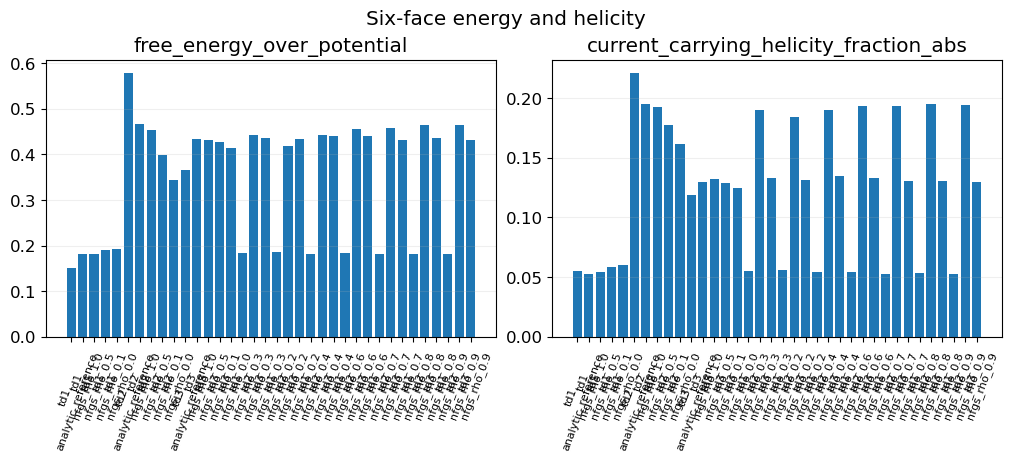

In [11]:
if 'helicity' in tables:
    display(tables['helicity'])
    plot_grouped(tables['helicity'],['free_energy_over_potential','current_carrying_helicity_fraction_abs'],'Six-face energy and helicity'); plt.show()

## Sensitivity of the practical weight choice

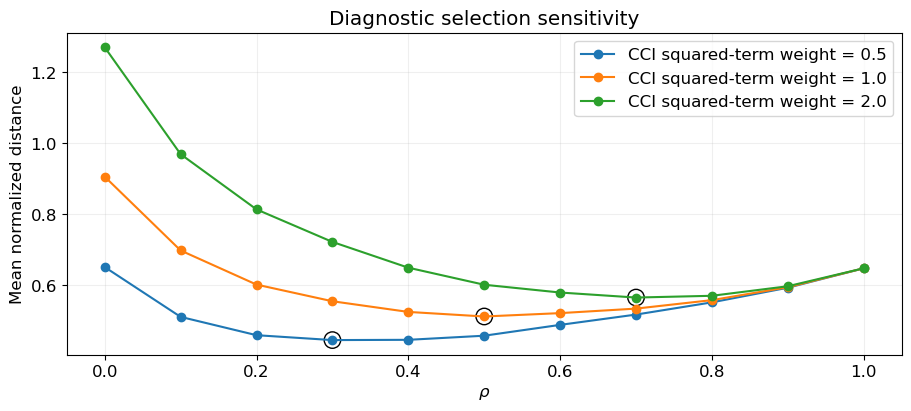

,cci_squared_term_weight,rho,mean_distance
3,0.5,0.3,0.446200
16,1.0,0.5,0.512528
29,2.0,0.7,0.565755


In [12]:
if 'selection' in tables:
    plot_selection(tables['selection']); plt.show()
    display(tables['selection'].loc[tables['selection'].groupby('cci_squared_term_weight').mean_distance.idxmin()])

## Additional numerical experiments

The extended campaign provides the factorized bridge and resolution matrix. These are distinct from the primary manuscript weight scan.

In [13]:
for key in ['regularization','factorized','resolution']:
    if key in tables:
        print(key); display(tables[key])
if (RESULT_ROOT/'reproduction_audit.json').exists(): display(json.loads((RESULT_ROOT/'reproduction_audit.json').read_text()))

regularization


,benchmark,alpha_clip_scale,weak_field_floor_B2,stop_mode,stop_reason,selected_state,n_iters,C_vec,epsilon,sigma_J,sigma_J_common_fd2,alpha_clip_fraction_final,alpha_clip_fraction_max,weak_field_floor_fraction_final,weak_field_floor_fraction_max,B_harm_over_Bobs_rms,Jz_projected_out_over_Jz_rms,bottom_horizontal_reconstruction_ratio,family,alpha_scale_requested
0,td1,0.5,1.000000e-20,sigma_best,sigma_stall,best_sigma,148,0.980538,0.727651,0.183989,0.193692,4.671704e-04,0.000467,0.0,0.0,0.037497,0.000087,0.037497,td,0.5
1,td2,0.5,1.000000e-20,sigma_best,sigma_stall,best_sigma,408,0.984107,0.875282,0.071031,0.075176,2.811139e-04,0.000308,0.0,0.0,0.022266,0.000154,0.022266,td,0.5
2,td3,0.5,1.000000e-20,sigma_best,sigma_stall,best_sigma,87,0.973562,0.824389,0.102219,0.110195,7.381976e-05,0.000107,0.0,0.0,0.024863,0.649143,0.024863,td,0.5
3,low_lou_c2,0.5,1.000000e-20,sigma_best,sigma_stall,best_sigma,60,0.995142,1.002660,0.083661,0.164198,4.425239e-04,0.000598,0.0,0.0,0.008832,0.000042,0.008832,low_lou,0.5
4,low_lou_ll1,0.5,1.000000e-20,sigma_best,sigma_improvement_tol,best_sigma,51,0.991446,0.982790,0.105141,0.187343,4.219162e-04,0.000657,0.0,0.0,0.012474,0.000031,0.012474,low_lou,0.5
5,low_lou_ll2,0.5,1.000000e-20,sigma_best,sigma_stall,best_sigma,47,0.998056,1.036005,0.096856,0.181822,4.349316e-04,0.000435,0.0,0.0,0.019590,0.000009,0.019590,low_lou,0.5
6,td1,1.0,1.000000e-20,sigma_best,sigma_stall,best_sigma,98,0.979746,0.723790,0.185992,0.195864,3.792930e-05,0.000038,0.0,0.0,0.037497,0.000087,0.037497,td,1.0
7,td2,1.0,1.000000e-20,sigma_best,sigma_stall,best_sigma,275,0.985442,0.872525,0.071434,0.075712,7.367338e-05,0.000089,0.0,0.0,0.022266,0.000154,0.022266,td,1.0
8,td3,1.0,1.000000e-20,sigma_best,sigma_stall,best_sigma,89,0.974657,0.821772,0.100565,0.108143,1.000215e-05,0.000021,0.0,0.0,0.024863,0.649143,0.024863,td,1.0
9,low_lou_c2,1.0,1.000000e-20,sigma_best,sigma_stall,best_sigma,59,0.995177,1.002643,0.083544,0.163789,4.989241e-05,0.000117,0.0,0.0,0.008832,0.000042,0.008832,low_lou,1.0


factorized


,run_id,config_hash,variant_id,changed_factor,benchmark,source_partition_mode,init_mode,poloidal_update_mode,rho,horizontal_zero_mode_policy,...,iterations_per_s,peak_memory_bytes,C_vec,C_CS,Eprime_n,Eprime_m,epsilon,sigma_J,sigma_J_common_fd2,cache_status
0,f1__td1__float32__34c829b9c162,34c829b9c162a00c0795286e4aab4704da322c365b0013...,F1,same-code single-field PT bridge,td1,legacy_single_field,cfcf,two_stage,0.0,omit,...,10.692136,1870262272,0.961045,0.931105,0.656772,0.581901,0.669915,0.103540,0.105736,computed
1,f1__td2__float32__51d23f975cb4,51d23f975cb4bf083fd5e79fa2b6930ff6ba365813ee93...,F1,same-code single-field PT bridge,td2,legacy_single_field,cfcf,two_stage,0.0,omit,...,11.736754,1870262272,0.955792,0.953175,0.736066,0.717978,0.852984,0.057448,0.058481,computed
2,f1__td3__float32__dbb9f7657e51,dbb9f7657e519c8acf2abc633fcd812c60d427b74a748f...,F1,same-code single-field PT bridge,td3,legacy_single_field,cfcf,two_stage,0.0,omit,...,3.335522,7380871680,0.963990,0.923439,0.670837,0.571969,0.699151,0.168096,0.166725,computed
3,f2__td1__float32__169e091d0bf1,169e091d0bf1b8eee61252e7f9be2c4d6b96cd03c379fa...,F2,direct scalar solve,td1,legacy_single_field,cfcf,direct,0.0,omit,...,12.135175,1870262272,0.961046,0.931096,0.656789,0.581920,0.669949,0.103481,0.105673,computed
4,f2__td2__float32__121de51be856,121de51be85611b44c6ec60b41477abbb8bcbc1ada278e...,F2,direct scalar solve,td2,legacy_single_field,cfcf,direct,0.0,omit,...,12.353634,1870262272,0.955776,0.953166,0.736019,0.717931,0.852997,0.057402,0.058434,computed
5,f2__td3__float32__c312a7f12f3d,c312a7f12f3d2c5eff8524d5066dbbaedd2d63952785fe...,F2,direct scalar solve,td3,legacy_single_field,cfcf,direct,0.0,omit,...,3.546407,7380488192,0.964469,0.923908,0.671548,0.571818,0.700415,0.167476,0.166135,computed
6,f3__td1__float32__65975a084b56,65975a084b5687f75563c45f4b9f53915b3cc6c663879c...,F3,Gaussian source partition,td1,gaussian_separated,cfcf,direct,0.0,omit,...,13.460166,1947659776,0.976243,0.968055,0.723691,0.668599,0.719337,0.113936,0.116660,computed
7,f3__td2__float32__1f2686beb4dd,1f2686beb4dd20c488f2c895d026d2ceb479da363cc308...,F3,Gaussian source partition,td2,gaussian_separated,cfcf,direct,0.0,omit,...,13.191458,1947659776,0.959908,0.957584,0.750658,0.733662,0.863994,0.055600,0.056774,computed
8,f3__td3__float32__03fae73efe90,03fae73efe90703d336330176c2cd482bc6770842b445e...,F3,Gaussian source partition,td3,gaussian_separated,cfcf,direct,0.0,omit,...,3.457987,7686840320,0.969280,0.955425,0.698893,0.625698,0.705927,0.184741,0.181601,computed
9,f4__td1__float32__e5424a8777fd,e5424a8777fdd0aa95aa66d427236e09d176b453dee95c...,F4,GS-CFCF initializer,td1,gaussian_separated,gs_cfcf,direct,0.0,omit,...,12.352991,1947659776,0.976065,0.967722,0.723196,0.668055,0.719521,0.114471,0.117045,computed


resolution


,run_id,config_hash,benchmark,requested_ratio,realized_interval_density_ratio_xyz,grid_xyz,calculation_grid_xyz,spacing_xyz_mm,metric_shape_zyx,metric_slices_zyx,...,Eprime_n,Eprime_m,epsilon,sigma_J,cache_status,ratio,rho_reference,rho_realized,gamma,output_dir
0,td1__r0p5__rho0__76x126x51__float32__af6049b1e209,af6049b1e209085755310f27d5ae7ea89994ef323b1071...,td1,0.50,"[0.5033557046979866, 0.5020080321285141, 0.505...","[76, 126, 51]","[98, 130, 65]","[4.800000000000011, 4.812885906040265, 4.78389...","[51, 63, 38]","[[0, 51, null], [32, 95, null], [19, 57, null]]",...,0.728670,0.670259,0.726159,0.124490,computed,0.50,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
1,td1__r0p75__rho0__113x188x75__float32__3aa1273...,3aa127342434079fa25235b406b9a06a77b2207e0cc7ed...,td1,0.75,"[0.7516778523489933, 0.751004016064257, 0.7474...","[113, 188, 75]","[129, 194, 97]","[3.2142857142857224, 3.2171697232889755, 3.232...","[75, 94, 56]","[[0, 75, null], [47, 141, null], [29, 85, null]]",...,0.750972,0.697663,0.739697,0.092096,computed,0.75,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
2,td1__r1__rho0__150x250x100__float32__78bcf0fffcf2,78bcf0fffcf2888d6eaffc9e7f176a3107aeb0d3e77a6f...,td1,1.00,"[1.0, 1.0, 1.0]","[150, 250, 100]","[194, 258, 129]","[2.4161073825503365, 2.416107382550308, 2.4161...","[100, 125, 75]","[[0, 100, null], [63, 188, null], [38, 113, nu...",...,0.728526,0.669858,0.721418,0.089944,computed,1.00,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
3,td2__r0p5__rho0__76x126x51__float32__459500946f04,459500946f04a443b9bc1fc4c4a2bb3de1b4efa3baf621...,td2,0.50,"[0.5033557046979866, 0.5020080321285141, 0.505...","[76, 126, 51]","[98, 130, 65]","[4.800000000000011, 4.812885906040265, 4.78389...","[15, 33, 33]","[[0, 15, null], [46, 79, null], [21, 54, null]]",...,0.735537,0.721902,0.825680,0.087080,computed,0.50,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
4,td2__r0p75__rho0__113x188x75__float32__5504855...,55048556c481d014b0564cd9bfb82b6490042097adf47c...,td2,0.75,"[0.7516778523489933, 0.751004016064257, 0.7474...","[113, 188, 75]","[129, 194, 97]","[3.2142857142857224, 3.2171697232889755, 3.232...","[23, 50, 50]","[[0, 23, null], [68, 118, null], [31, 81, null]]",...,0.818306,0.815153,0.864064,0.049841,computed,0.75,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
5,td2__r1__rho0__150x250x100__float32__39b5a6864ee6,39b5a6864ee64cad3414e044e929b4907091822c361aab...,td2,1.00,"[1.0, 1.0, 1.0]","[150, 250, 100]","[194, 258, 129]","[2.4161073825503365, 2.416107382550308, 2.4161...","[30, 66, 66]","[[0, 30, null], [91, 157, null], [41, 107, null]]",...,0.732896,0.713540,0.877132,0.062972,computed,1.00,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
6,td3__r0p5__rho0__129x176x101__float32__f956fb0...,f956fb01580b6ee8267e1c0928f201f6c23f4fcd11c1fb...,td3,0.50,"[0.5019607843137255, 0.501432664756447, 0.5025...","[129, 176, 101]","[129, 194, 129]","[2.8125, 2.815462184873951, 2.8094117647058825]","[101, 88, 65]","[[0, 101, null], [44, 132, null], [32, 97, null]]",...,0.711475,0.634648,0.725665,0.146912,computed,0.50,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
7,td3__r0p75__rho0__192x263x150__float32__cc7521...,cc7521e2e66a8b8c8c25a737de30ad21eebe3973146863...,td3,0.75,"[0.7490196078431373, 0.7507163323782235, 0.748...","[192, 263, 150]","[194, 385, 193]","[1.8848167539267138, 1.8805568028738264, 1.885...","[150, 132, 96]","[[0, 150, null], [66, 198, null], [48, 144, nu...",...,0.682011,0.606996,0.693938,0.168489,computed,0.75,0.0,0.000000,0.000000,/home/kim-yj/Projects/2026/NFPT_CCU_RBSL_valid...
8,td3__r1__rho0__256x350x200__float32__020742ddc614,020742ddc614b88e875740a0ee718360bb6cb3f80f086d...,td3,1.00,"[1.0, 1.0, 1.0]","[256, 350, 200]","[258, 386, 257]","[1.411764705882348, 1.411764705882348, 1.41176...","[200, 175, 128]","[[0, 200, null], [88, 263, null]

## Field structure and Q maps

Archived views below retain the original manuscript rendering. A fresh campaign produces common-seed field-line and diagnostic views in its own figures directory; the new rendering does not alter the numerical metrics.

figure_nfpt_fieldlines_readable.png


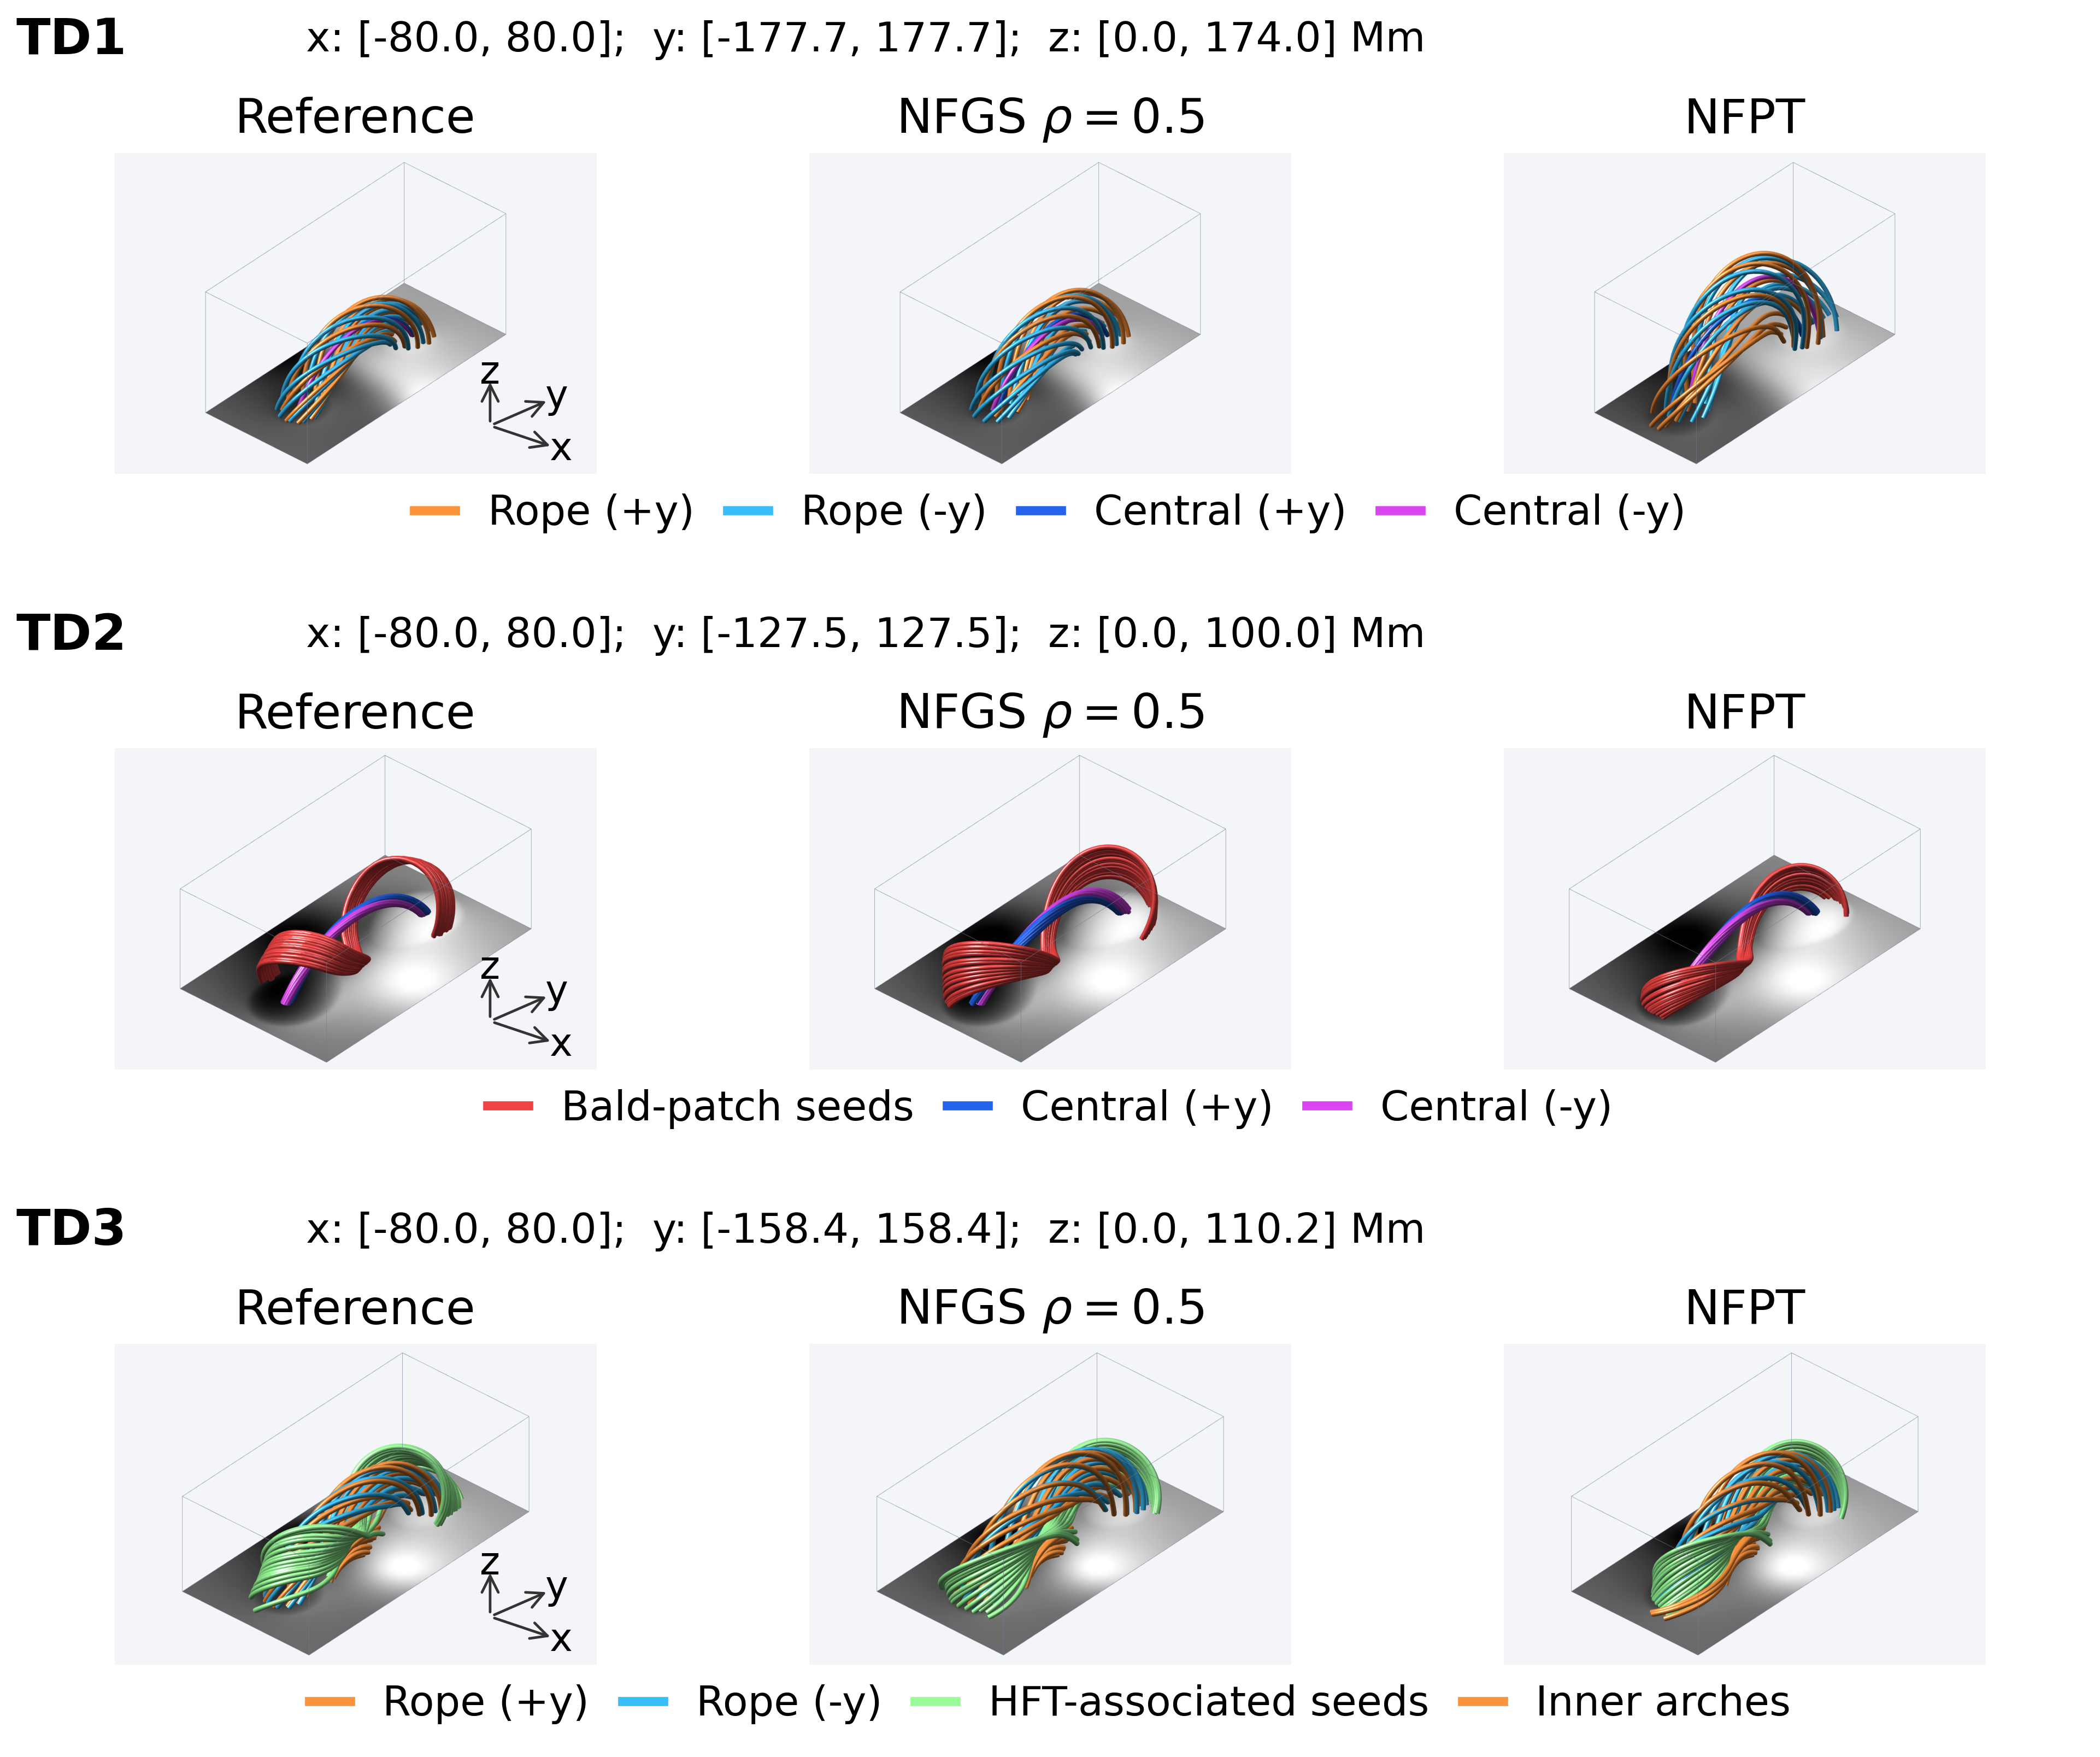

figure_qmaps_readable.png


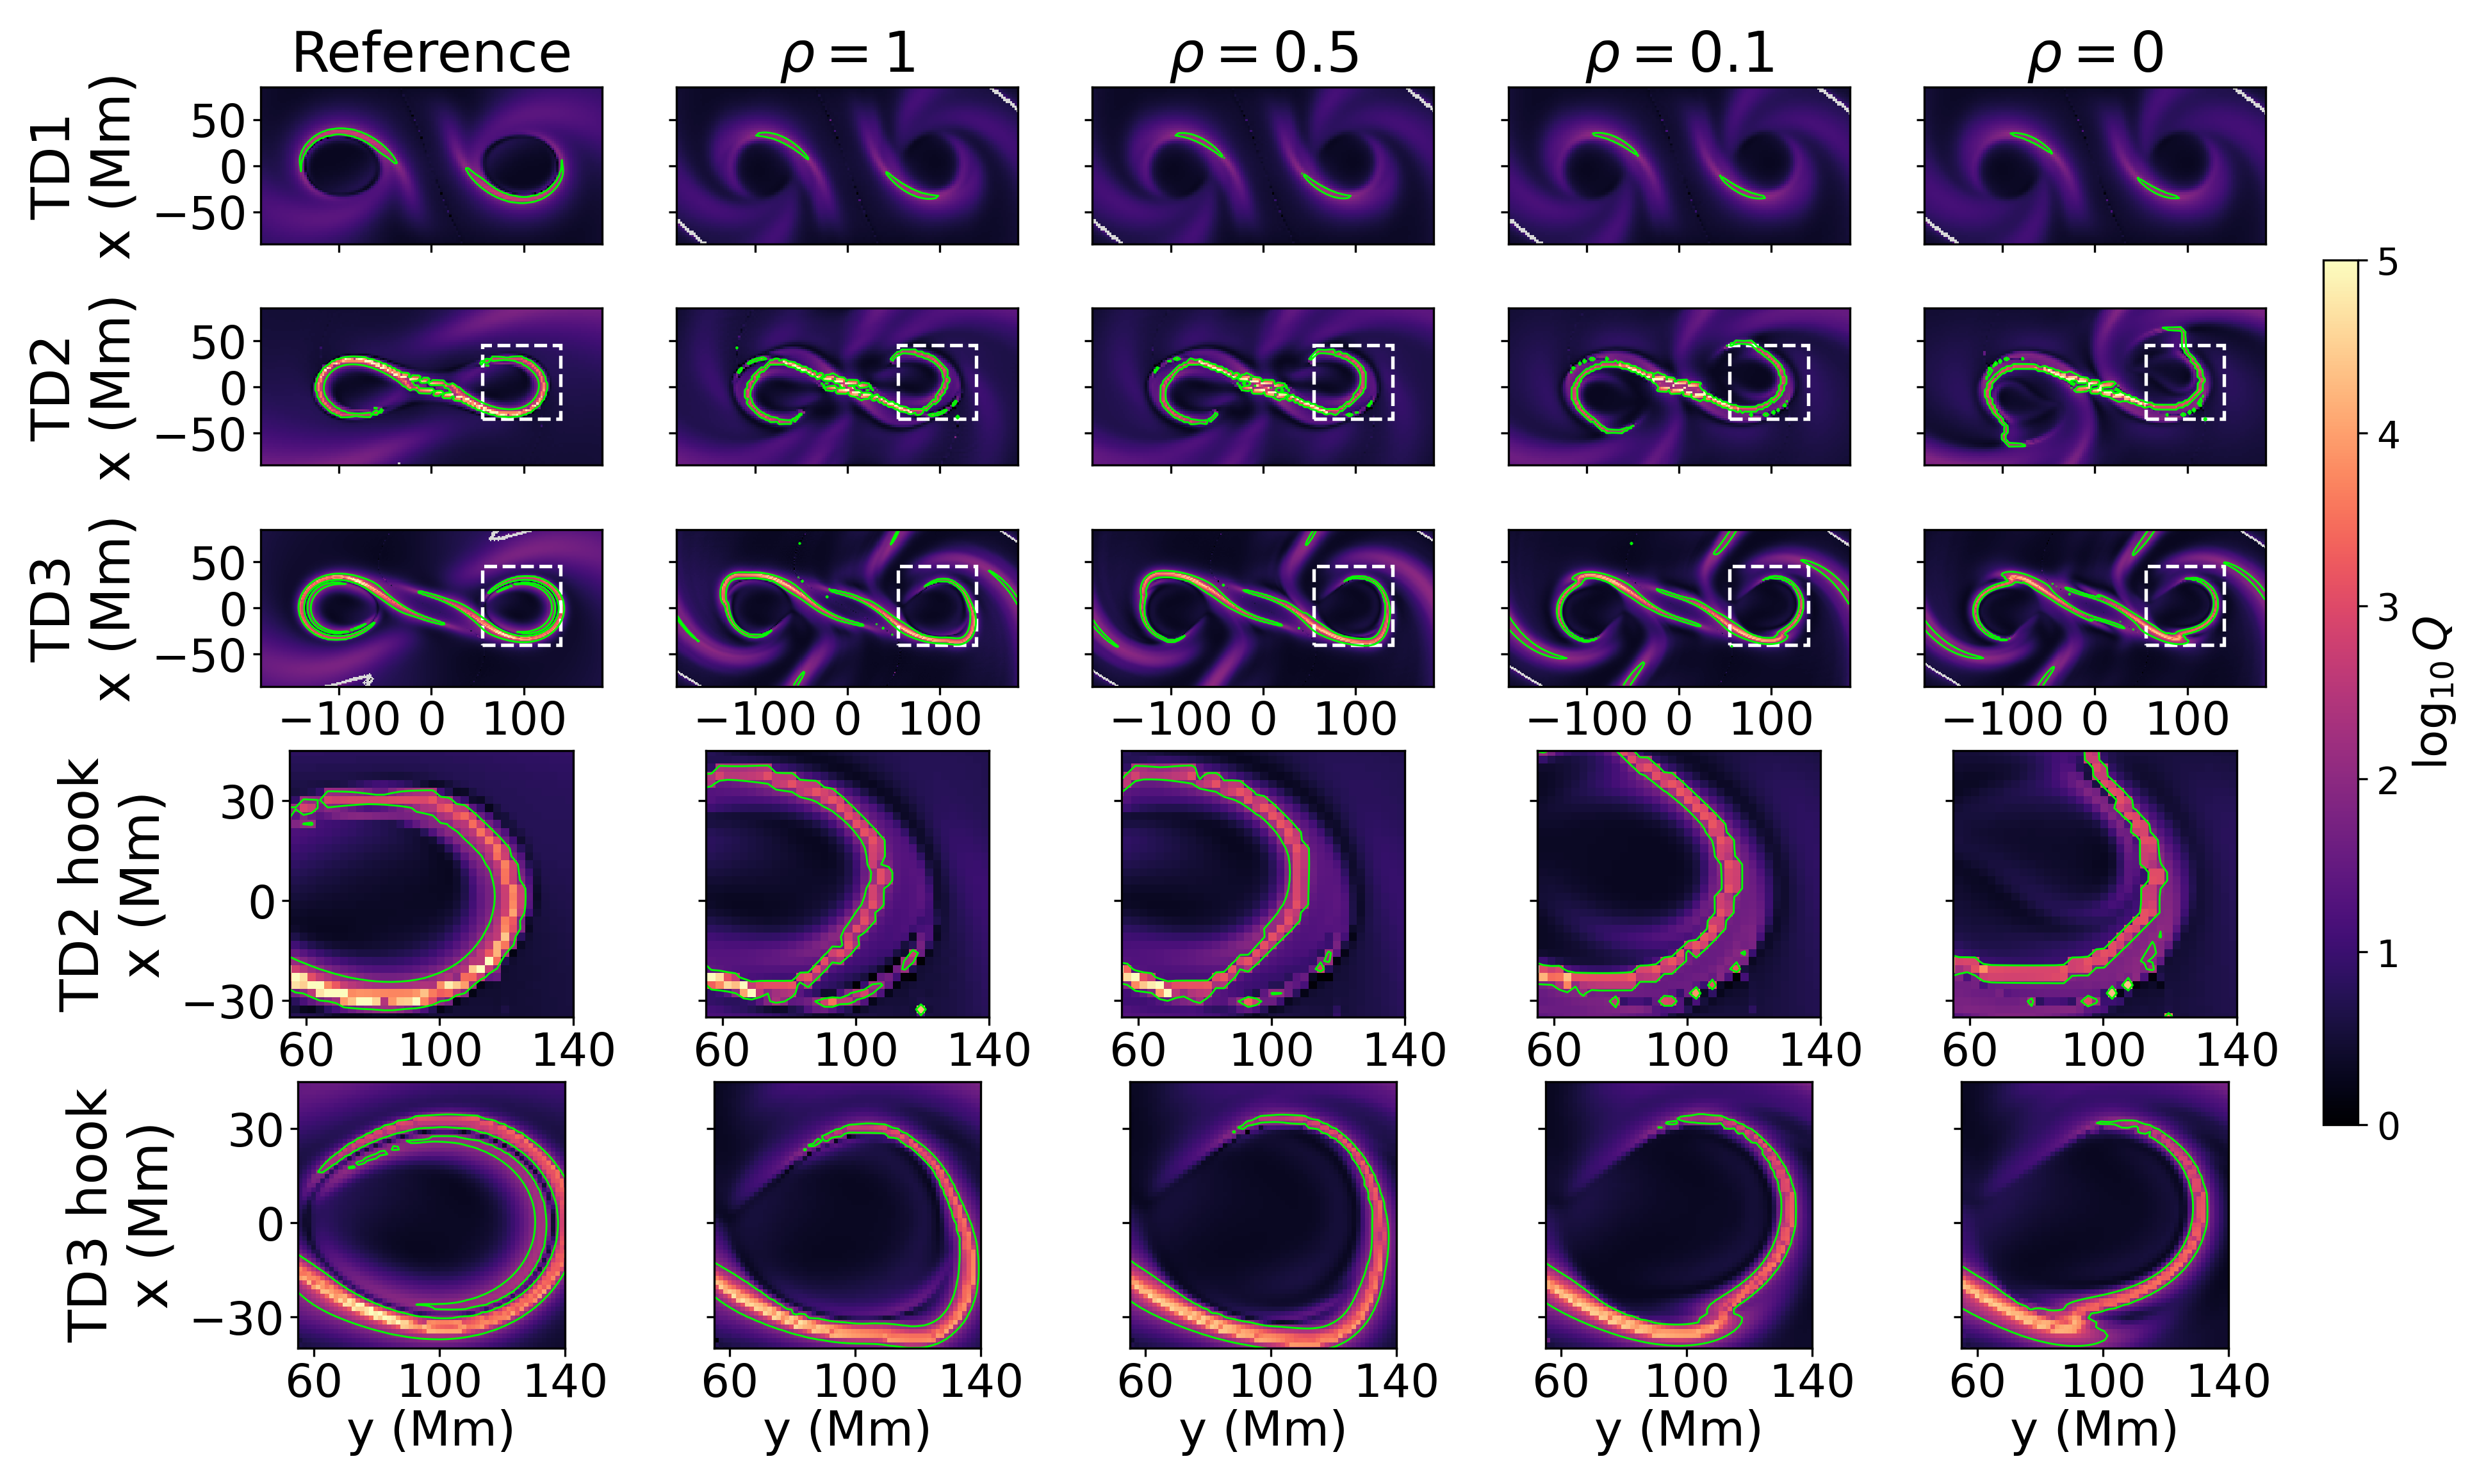

figure_td_fieldlines_readable.png


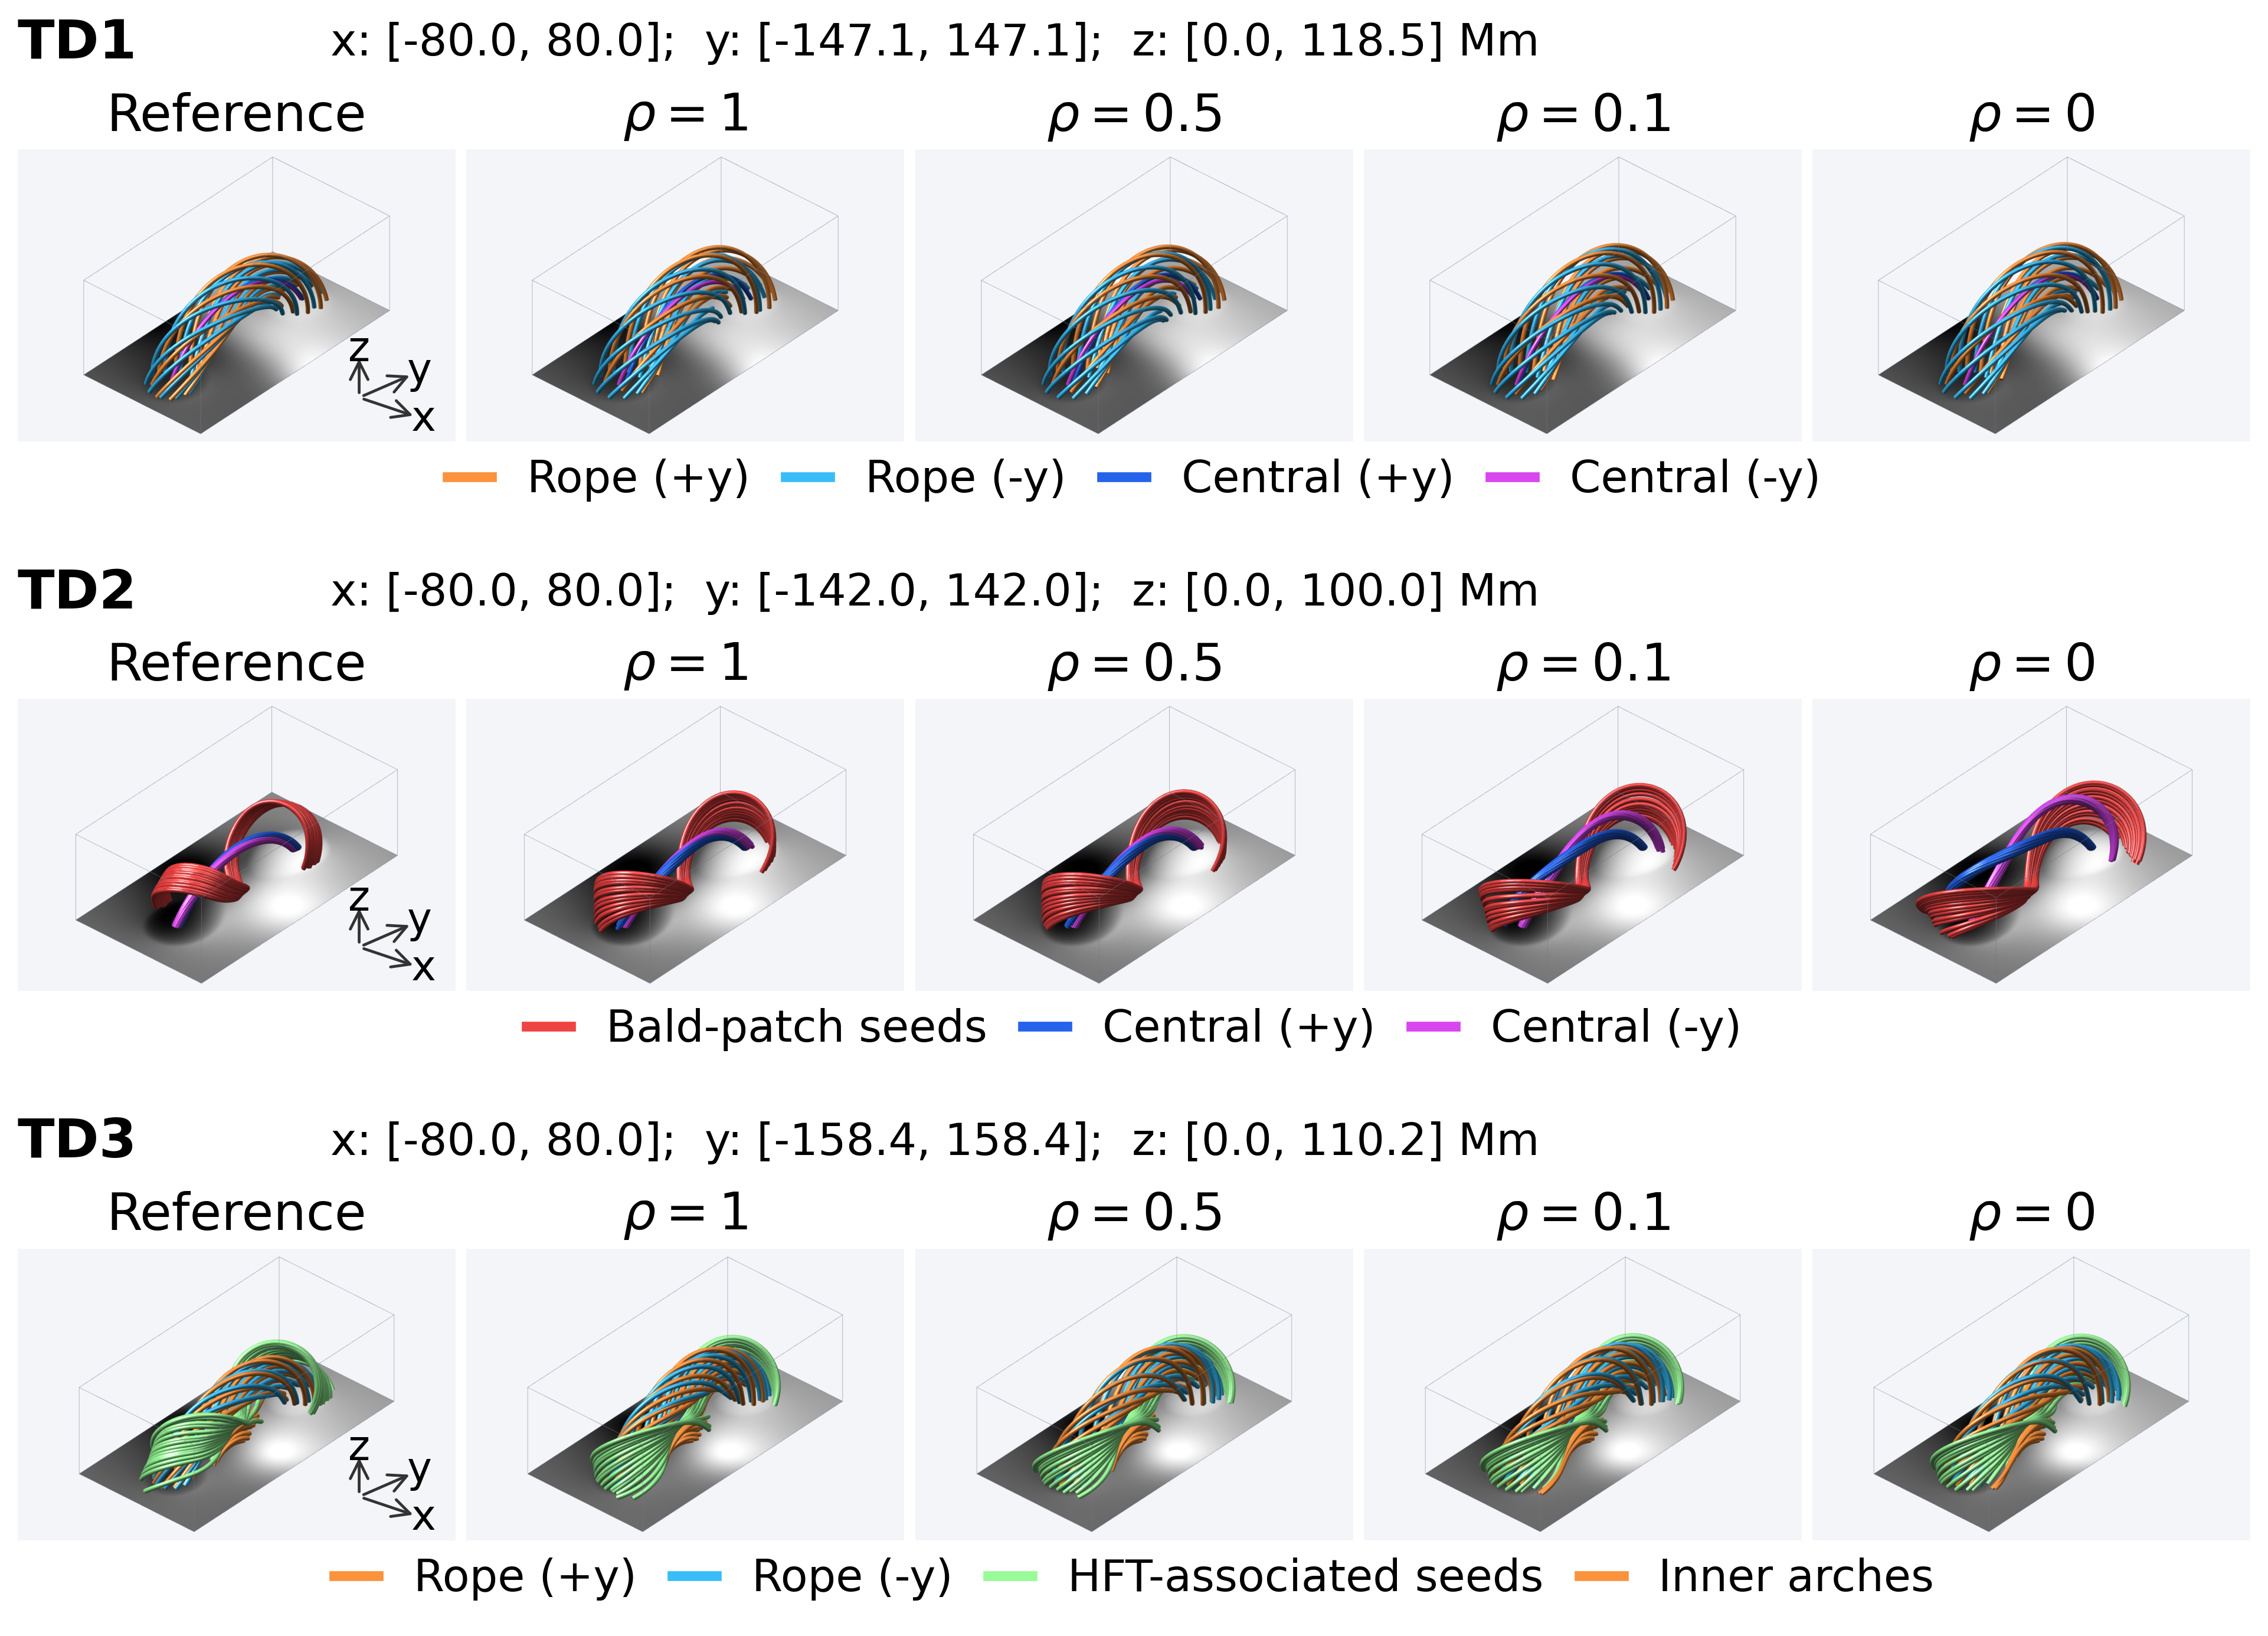

In [14]:
from IPython.display import Image
figure_dir=RESULT_ROOT/'figures'
if figure_dir.exists():
    for file in sorted(figure_dir.glob('*.png')):
        print(file.name); display(Image(filename=str(file),width=1000))
else: print('No field or map views in this campaign yet.')